# Clasificación de residuos y envases mediante una CNN
**Portafolio de implementación · Deep learning · Trabajo individual**

## 1. Introducción
La separación de residuos requiere distinguir materiales y tipos de envases. El objetivo es entrenar una red neuronal convolucional que asigne una imagen a una de seis categorías: botellas de plástico, envases de cartón para bebidas, envases metálicos, basura doméstica, papel/cartón y vidrio.



Se implementa un modelo inicial, se realiza una iteración de ajuste y se evalúa el modelo elegido con una partición de prueba reservada. La aplicación recibe una ruta de imagen y devuelve su clasificación.

## 2. Datos
### Fuente y categorías
Se utiliza **Garbage classification dataset**, publicado por **Manon_str** en [Kaggle](https://www.kaggle.com/datasets/manonstr/tipe-webscraping).

In [ ]:
%pip install -q kagglehub

In [ ]:
import kagglehub

path = kagglehub.dataset_download("manonstr/tipe-webscraping")

print("Path to dataset files:", path)

100%|██████████| 1.12G/1.12G [00:15<00:00, 77.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/manonstr/tipe-webscraping/versions/12


In [ ]:
from pathlib import Path

dataset_dir = Path(path)

print("Contenido principal:")
for item in sorted(dataset_dir.iterdir()):
    tipo = "Carpeta" if item.is_dir() else "Archivo"
    print(f"{tipo}: {item.name}")

print("\nSubcarpetas:")
for item in sorted(dataset_dir.iterdir()):
    if item.is_dir():
        subcarpetas = sorted(p.name for p in item.iterdir() if p.is_dir())
        print(f"{item.name}: {subcarpetas}")

Contenido principal:
Carpeta: 1024+

Subcarpetas:
1024+: ['entrainement', 'test']


In [ ]:
from pathlib import Path

raiz = Path(path) / "1024+"
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for nombre in ["entrainement", "test"]:
    carpeta = raiz / nombre
    print(f"\n📁 {nombre}")

    for elemento in sorted(carpeta.iterdir()):
        if elemento.is_dir():
            cantidad = sum(
                1 for archivo in elemento.rglob("*")
                if archivo.is_file()
                and archivo.suffix.lower() in extensiones
            )
            print(f"  {elemento.name}: {cantidad} imágenes")
        else:
            print(f"  Archivo: {elemento.name}")


📁 entrainement
  Bouteille_plastique: 1437 imágenes
  Brique_en_carton: 1047 imágenes
  Emballage_metallique: 1217 imágenes
  Ordure_m∩┐╜nag∩┐╜re: 1050 imágenes
  Papier_Carton: 1043 imágenes
  Verre: 1225 imágenes

📁 test
  Bouteille_plastique: 35 imágenes
  Brique_en_carton: 15 imágenes
  Emballage_metallique: 25 imágenes
  Ordure_m∩┐╜nag∩┐╜re: 10 imágenes
  Papier_Carton: 44 imágenes
  Verre: 28 imágenes


### Exploración visual
Los ejemplos permiten inspeccionar el contenido y detectar imágenes poco representativas. Varias fotografías muestran productos limpios o fondos sencillos. Esto limita el alcance de cualquier conclusión sobre residuos sucios, aplastados o en escenas reales.

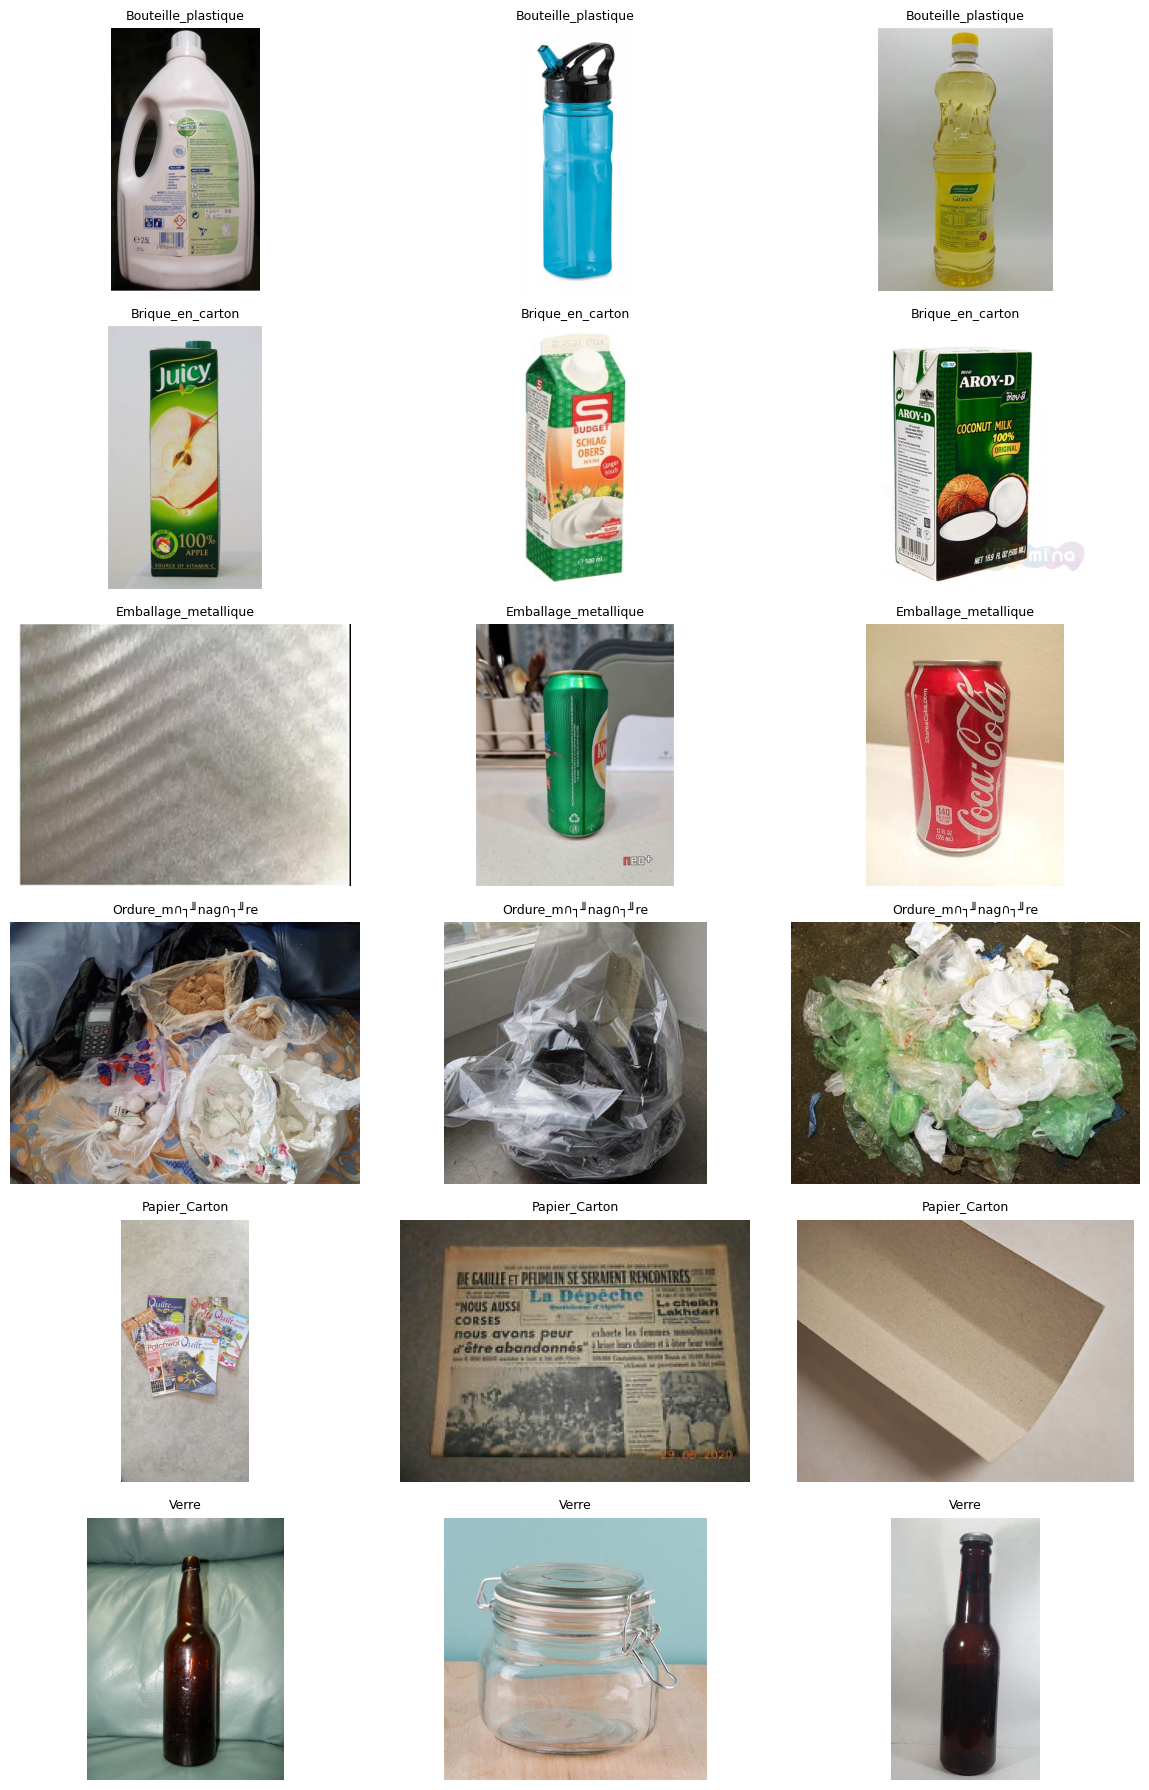

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

carpeta_train = Path(path) / "1024+" / "entrainement"
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

categorias = sorted(
    carpeta for carpeta in carpeta_train.iterdir()
    if carpeta.is_dir()
)

rng = random.Random(42)

fig, axes = plt.subplots(
    len(categorias), 3,
    figsize=(12, 3 * len(categorias)),
    squeeze=False
)

for fila, categoria in enumerate(categorias):
    imagenes = sorted(
        archivo for archivo in categoria.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in extensiones
    )

    ejemplos = rng.sample(imagenes, min(3, len(imagenes)))

    for columna, ax in enumerate(axes[fila]):
        ax.axis("off")

        if columna < len(ejemplos):
            try:
                with Image.open(ejemplos[columna]) as imagen:
                    ax.imshow(imagen.convert("RGB"))
                ax.set_title(categoria.name, fontsize=9)
            except Exception as error:
                ax.set_title(f"No se pudo abrir: {type(error).__name__}")

plt.tight_layout()
plt.show()

### Integridad, duplicados y conflictos
Se verificaron las 7176 imágenes y ninguna resultó ilegible. La advertencia de Pillow sobre transparencia no impidió su lectura. Para la entrada del modelo se transforma cada imagen a RGBA, se compone sobre fondo blanco y se convierte a RGB.

Se generó una huella SHA-256 a partir del tamaño y los píxeles RGB. Se encontraron **126 grupos duplicados y 133 copias adicionales**, sin duplicados exactos compartidos entre las carpetas de entrenamiento y prueba. Esta técnica no detecta necesariamente versiones recortadas, redimensionadas o recomprimidas.



In [ ]:
from pathlib import Path
from PIL import Image

raiz = Path(path) / "1024+"
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

archivos = sorted(
    archivo for archivo in raiz.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() in extensiones
)

danados = []

for archivo in archivos:
    try:
        with Image.open(archivo) as imagen:
            imagen.verify()


        with Image.open(archivo) as imagen:
            imagen.convert("RGB").load()

    except Exception as error:
        danados.append((str(archivo.relative_to(raiz)), str(error)))

print(f"Imágenes revisadas: {len(archivos)}")
print(f"Imágenes que no se pudieron leer: {len(danados)}")

for nombre, error in danados[:20]:
    print(f"\n{nombre}\n  {error}")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Imágenes revisadas: 7176
Imágenes que no se pudieron leer: 0


In [ ]:
import hashlib
from collections import defaultdict
from PIL import Image

grupos = defaultdict(list)

for archivo in archivos:
    with Image.open(archivo) as imagen:
        # Unificar transparencia sobre fondo blanco
        rgba = imagen.convert("RGBA")
        fondo = Image.new("RGBA", rgba.size, "white")
        rgb = Image.alpha_composite(fondo, rgba).convert("RGB")

        huella = hashlib.sha256()
        huella.update(str(rgb.size).encode())
        huella.update(rgb.tobytes())

    grupos[huella.hexdigest()].append(
        archivo.relative_to(raiz)
    )

duplicados = [
    rutas for rutas in grupos.values()
    if len(rutas) > 1
]

cruces = [
    rutas for rutas in duplicados
    if len({ruta.parts[0] for ruta in rutas}) > 1
]

conflictos = [
    rutas for rutas in duplicados
    if len({ruta.parts[1] for ruta in rutas}) > 1
]

print("Grupos de imágenes duplicadas:", len(duplicados))
print(
    "Copias adicionales:",
    sum(len(grupo) - 1 for grupo in duplicados)
)
print("Grupos compartidos entre entrenamiento y prueba:", len(cruces))
print("Grupos con etiquetas diferentes:", len(conflictos))

print("\nEjemplos de duplicados:")
for grupo in duplicados[:5]:
    print()
    for ruta in grupo:
        print(" ", ruta)

Grupos de imágenes duplicadas: 126
Copias adicionales: 133
Grupos compartidos entre entrenamiento y prueba: 0
Grupos con etiquetas diferentes: 2

Ejemplos de duplicados:

  entrainement/Bouteille_plastique/bouteille_plastique_111.jpeg
  entrainement/Bouteille_plastique/bouteille_plastique_112.jpeg
  entrainement/Bouteille_plastique/bouteille_plastique_216.jpeg

  entrainement/Bouteille_plastique/bouteille_plastique_1176.jpg
  entrainement/Bouteille_plastique/bouteille_plastique_291.jpg

  entrainement/Bouteille_plastique/bouteille_plastique_1177.jpg
  entrainement/Bouteille_plastique/bouteille_plastique_271.jpg

  entrainement/Bouteille_plastique/bouteille_plastique_1178.jpg
  entrainement/Bouteille_plastique/bouteille_plastique_355.jpg

  entrainement/Bouteille_plastique/bouteille_plastique_1195.jpg
  entrainement/Bouteille_plastique/bouteille_plastique_180.jpg


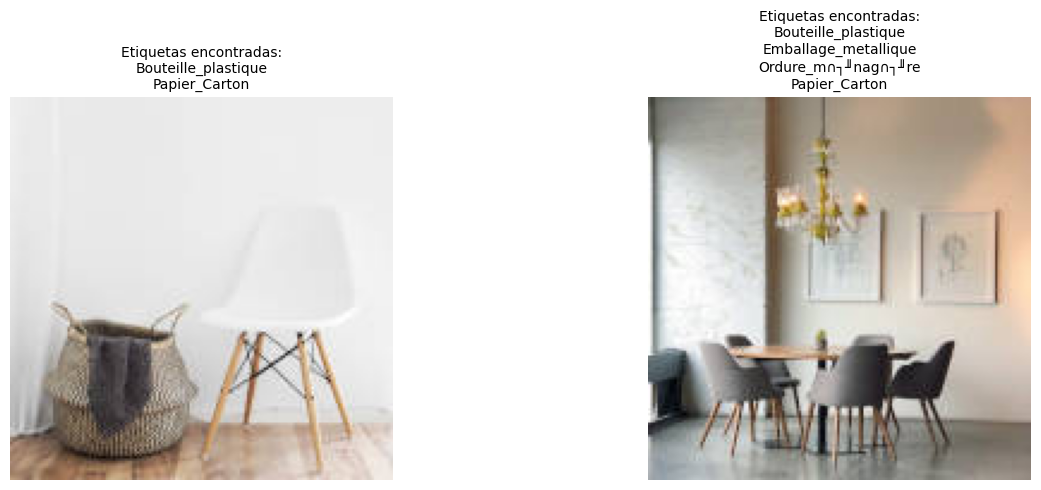


Conflicto 1:
  entrainement/Bouteille_plastique/bouteille_plastique_1244.jpg
  entrainement/Papier_Carton/Papier_carton_347.jpg

Conflicto 2:
  entrainement/Bouteille_plastique/bouteille_plastique_1260.jpg
  entrainement/Emballage_metallique/metal_333.jpg
  entrainement/Ordure_m∩┐╜nag∩┐╜re/Ordure_menagere_246.jpg
  entrainement/Papier_Carton/Papier_carton_378.jpg


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(
    1, len(conflictos),
    figsize=(7 * len(conflictos), 5),
    squeeze=False
)

for ax, grupo in zip(axes[0], conflictos):
    with Image.open(raiz / grupo[0]) as imagen:
        ax.imshow(imagen.convert("RGBA"))

    etiquetas = sorted({ruta.parts[1] for ruta in grupo})
    ax.set_title(
        "Etiquetas encontradas:\n" + "\n".join(etiquetas),
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

for numero, grupo in enumerate(conflictos, start=1):
    print(f"\nConflicto {numero}:")
    for ruta in grupo:
        print(" ", ruta)

In [ ]:
from collections import Counter

rutas_limpias = []
excluidas_conflicto = []
copias_omitidas = []

for grupo in grupos.values():


    rutas = sorted(grupo)

    etiquetas = {ruta.parts[1] for ruta in rutas}

    if len(etiquetas) > 1:
        # Excluir todas las copias con etiquetas contradictorias
        excluidas_conflicto.extend(rutas)
    else:
        # Conservar una sola imagen por grupo
        rutas_limpias.append(rutas[0])
        copias_omitidas.extend(rutas[1:])

print("Imágenes originales:", len(archivos))
print("Imágenes excluidas por conflicto:", len(excluidas_conflicto))
print("Copias repetidas omitidas:", len(copias_omitidas))
print("Imágenes disponibles:", len(rutas_limpias))

conteo = Counter(
    (ruta.parts[0], ruta.parts[1])
    for ruta in rutas_limpias
)

print("\nDistribución después de la limpieza:")
for (particion, categoria), cantidad in sorted(conteo.items()):
    print(f"{particion} | {categoria}: {cantidad}")

Imágenes originales: 7176
Imágenes excluidas por conflicto: 6
Copias repetidas omitidas: 129
Imágenes disponibles: 7041

Distribución después de la limpieza:
entrainement | Bouteille_plastique: 1388
entrainement | Brique_en_carton: 1013
entrainement | Emballage_metallique: 1208
entrainement | Ordure_m∩┐╜nag∩┐╜re: 1018
entrainement | Papier_Carton: 1040
entrainement | Verre: 1218
test | Bouteille_plastique: 35
test | Brique_en_carton: 14
test | Emballage_metallique: 25
test | Ordure_m∩┐╜nag∩┐╜re: 10
test | Papier_Carton: 44
test | Verre: 28


### Separación de datos
Después de la limpieza quedaron **7041 imágenes**. Se mantuvo la carpeta original de prueba y se dividió únicamente entrenamiento con `test_size=0.20`, estratificación por clase y `random_state=42`.

| Clase | Entrenamiento | Validación | Prueba |
|---|---:|---:|---:|
| Botellas de plástico | 1111 | 277 | 35 |
| Envases de cartón | 810 | 203 | 14 |
| Envases metálicos | 967 | 241 | 25 |
| Basura doméstica | 814 | 204 | 10 |
| Papel y cartón | 832 | 208 | 44 |
| Vidrio | 974 | 244 | 28 |
| **Total** | **5508** | **1377** | **156** |

Entrenamiento se usa para ajustar pesos; validación para seleccionar el ajuste y los mejores pesos; prueba para medir el modelo elegido.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Crear una tabla con las rutas seleccionadas después de la limpieza
df = pd.DataFrame([
    {
        "ruta": str(raiz / ruta),
        "categoria": ruta.parts[1],
        "origen": ruta.parts[0]
    }
    for ruta in rutas_limpias
])

# Mantener separado el conjunto de prueba original
df_desarrollo = df[df["origen"] == "entrainement"].copy()
df_test = df[df["origen"] == "test"].copy()

# Dividir únicamente los datos de desarrollo
df_train, df_val = train_test_split(
    df_desarrollo,
    test_size=0.20,
    random_state=42,
    stratify=df_desarrollo["categoria"]
)

# Reiniciar índices para facilitar su uso después
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Comprobar que ningún archivo esté en dos conjuntos
assert set(df_train["ruta"]).isdisjoint(df_val["ruta"])
assert set(df_train["ruta"]).isdisjoint(df_test["ruta"])
assert set(df_val["ruta"]).isdisjoint(df_test["ruta"])
assert len(df_train) + len(df_val) + len(df_test) == len(df)

print("Entrenamiento:", len(df_train))
print("Validación:", len(df_val))
print("Prueba:", len(df_test))

resumen = pd.concat(
    [
        df_train["categoria"].value_counts().rename("Entrenamiento"),
        df_val["categoria"].value_counts().rename("Validación"),
        df_test["categoria"].value_counts().rename("Prueba")
    ],
    axis=1
).fillna(0).astype(int).sort_index()

display(resumen)

Entrenamiento: 5508
Validación: 1377
Prueba: 156


,Entrenamiento,Validación,Prueba
categoria,,,
Bouteille_plastique,1111,277,35
Brique_en_carton,810,203,14
Emballage_metallique,967,241,25
Ordure_m∩┐╜nag∩┐╜re,814,204,10
Papier_Carton,832,208,44
Verre,974,244,28


### Preprocesamiento
Las imágenes se redimensionan a **160 × 160**, se convierten a RGB con fondo blanco para transparencia y se representan como `float32` en el intervalo 0–255. El redimensionamiento directo puede alterar la proporción original. La normalización a 0–1 se realiza dentro del modelo, una sola vez.

Las clases se codifican con enteros 0–5 en orden alfabético. Se usan lotes de 32, mezcla solo en entrenamiento y preparación anticipada con `prefetch`. No se aplicó aumento de datos. El uso de Pillow dentro de `tf.numpy_function` mantiene la lectura compatible con las imágenes revisadas, aunque puede limitar la velocidad de carga.

La salida conservada muestra GPU disponible en la sesión de esa celda; no registra el dispositivo específico utilizado durante cada entrenamiento.

In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image

tf.keras.utils.set_random_seed(42)

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# Crear una correspondencia fija entre categorías y números
clases = sorted(df_train["categoria"].unique())
clase_a_id = {
    nombre: numero
    for numero, nombre in enumerate(clases)
}

print("Categorías:")
for nombre, numero in clase_a_id.items():
    print(f"{numero}: {nombre}")

print("\nGPU disponible:", bool(tf.config.list_physical_devices("GPU")))


def leer_imagen_pil(ruta):
    """Abrir la imagen, resolver transparencia y unificar tamaño."""
    ruta = ruta.decode("utf-8")

    with Image.open(ruta) as imagen:
        rgba = imagen.convert("RGBA")
        fondo = Image.new("RGBA", rgba.size, "white")
        rgb = Image.alpha_composite(fondo, rgba).convert("RGB")

        rgb = rgb.resize(
            IMG_SIZE,
            resample=Image.Resampling.BILINEAR
        )

        return np.asarray(rgb, dtype=np.float32)


def preparar_imagen(ruta, etiqueta):
    imagen = tf.numpy_function(
        leer_imagen_pil,
        [ruta],
        Tout=tf.float32
    )

    imagen.set_shape((*IMG_SIZE, 3))
    return imagen, etiqueta


def crear_dataset(tabla, entrenamiento=False):
    rutas = tabla["ruta"].to_numpy(dtype=str)
    etiquetas = (
        tabla["categoria"]
        .map(clase_a_id)
        .to_numpy(dtype=np.int32)
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (rutas, etiquetas)
    )

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=len(tabla),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        preparar_imagen,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = crear_dataset(df_train, entrenamiento=True)
val_ds = crear_dataset(df_val)

# Revisar un lote de entrenamiento
imagenes, etiquetas = next(iter(train_ds))

print("\nForma de las imágenes:", imagenes.shape)
print("Forma de las etiquetas:", etiquetas.shape)
print(
    "Rango de píxeles:",
    float(tf.reduce_min(imagenes)),
    "a",
    float(tf.reduce_max(imagenes))
)

Categorías:
0: Bouteille_plastique
1: Brique_en_carton
2: Emballage_metallique
3: Ordure_m∩┐╜nag∩┐╜re
4: Papier_Carton
5: Verre

GPU disponible: True

Forma de las imágenes: (32, 160, 160, 3)
Forma de las etiquetas: (32,)
Rango de píxeles: 0.0 a 255.0


## 3. Desarrollo del modelo
### Arquitectura inicial
Se construyó una CNN desde cero con **28134 parámetros entrenables**.

| Componente | Configuración y propósito |
|---|---|
| Entrada y normalización | 160 × 160 × 3; `Rescaling(1/255)` |
| Bloque convolucional 1 | 16 filtros 3 × 3, ReLU, padding same; MaxPooling 2 × 2 |
| Bloque convolucional 2 | 32 filtros 3 × 3, ReLU, padding same; MaxPooling 2 × 2 |
| Bloque convolucional 3 | 64 filtros 3 × 3, ReLU, padding same; MaxPooling 2 × 2 |
| Resumen espacial | GlobalAveragePooling2D |
| Clasificador | Dense de 64 unidades ReLU; Dense de 6 unidades softmax |

Las convoluciones aprenden patrones locales y pooling reduce la resolución espacial. GlobalAveragePooling resume cada mapa y evita una capa Flatten con un gran número de conexiones. La salida softmax produce puntuaciones para las seis clases. Su valor máximo no es una garantía calibrada de acierto.

La arquitectura cumple el requisito de capas especializadas y no está formada únicamente por capas densas. Se usa Adam con tasa 0.001 y `sparse_categorical_crossentropy`, apropiada para etiquetas enteras mutuamente excluyentes.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

modelo_inicial = keras.Sequential([
    keras.Input(shape=(*IMG_SIZE, 3)),

    layers.Rescaling(1.0 / 255),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(clases), activation="softmax")
], name="cnn_inicial")

modelo_inicial.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_inicial.summary()

Model: "cnn_inicial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,134 (109.90 KB)

 Trainable params: 28,134 (109.90 KB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento y evaluación inicial
Se definió un máximo de 25 épocas y EarlyStopping sobre `val_loss`, con paciencia 5 y recuperación de los mejores pesos. El entrenamiento completó las 25 épocas. La época 24 tuvo la menor pérdida de validación y sus pesos se recuperaron al terminar.

**Resultado inicial:** exactitud de validación **69.57 %** y pérdida **0.797298**. La pérdida de validación disminuyó de 1.6254 en la primera época a 0.7973 en la época 24; las últimas épocas aún mostraban mejoras. Los registros por época se conservan a continuación como evidencia del proceso.

In [ ]:

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

historial_inicial = modelo_inicial.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stopping]
)

# Evaluar la versión con los mejores pesos recuperados
loss_inicial, acc_inicial = modelo_inicial.evaluate(
    val_ds,
    verbose=0
)

print(f"\nPérdida en validación: {loss_inicial:.4f}")
print(f"Exactitud en validación: {acc_inicial:.2%}")

Epoch 1/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 136s 704ms/step - accuracy: 0.2801 - loss: 1.7032 - val_accuracy: 0.3079 - val_loss: 1.6254
Epoch 2/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 131s 758ms/step - accuracy: 0.3673 - loss: 1.5457 - val_accuracy: 0.3725 - val_loss: 1.5419
Epoch 3/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 128s 742ms/step - accuracy: 0.4198 - loss: 1.4489 - val_accuracy: 0.3842 - val_loss: 1.5320
Epoch 4/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 130s 750ms/step - accuracy: 0.4557 - loss: 1.3952 - val_accuracy: 0.4691 - val_loss: 1.3828
Epoch 5/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 113s 651ms/step - accuracy: 0.4880 - loss: 1.3141 - val_accuracy: 0.4800 - val_loss: 1.3164
Epoch 6/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 111s 641ms/step - accuracy: 0.5238 - loss: 1.2383 - val_accuracy: 0.5265 - val_loss: 1.2440
Epoch 7/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 131s 750ms/step - accuracy: 0.5443 - loss: 1.1821 - val_accuracy: 0.5432 - val_loss: 1.1998
Epoch 8/25
173/173 ━━━━━━━━━━━━━━━━━━━━ 143s 764ms/step - accuracy: 0.5628 -

### Persistencia del modelo inicial
Las siguientes celdas guardaron el modelo inicial, el orden de las clases y su historial en Google Drive. Un archivo `.keras` contiene arquitectura y pesos

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import json

carpeta_modelos = Path("/content/drive/MyDrive/Proyecto_Residuos")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

modelo_inicial.save(carpeta_modelos / "modelo_inicial.keras")

# Guardar el orden de las categorías para interpretar predicciones
with open(carpeta_modelos / "clases.json", "w", encoding="utf-8") as archivo:
    json.dump(clases, archivo, ensure_ascii=False, indent=2)

# Guardar las curvas y métricas de cada época
with open(carpeta_modelos / "historial_inicial.json", "w") as archivo:
    json.dump(historial_inicial.history, archivo)

print("Modelo, categorías e historial guardados.")

Modelo, categorías e historial guardados.


## 4. Ajuste del modelo
Se clonó la arquitectura y se copiaron los mejores pesos iniciales. Se creó un nuevo optimizador Adam con tasa **0.0003**, frente a 0.001, y se permitió hasta 15 épocas adicionales. Se mantuvieron datos, arquitectura, lotes y criterio EarlyStopping.

La hipótesis fue que actualizaciones más pequeñas permitirían refinar los pesos después del aprendizaje inicial. El nuevo optimizador reinicia su estado interno. El entrenamiento terminó tras **11 épocas**, recuperando los pesos de la época 6 por menor `val_loss`.

| Versión | Tasa de aprendizaje | Exactitud de validación | Pérdida de validación |
|---|---:|---:|---:|
| Inicial | 0.001 | 69.5715 % | 0.797298 |
| Ajustada | 0.0003 | 70.8787 % | 0.738374 |

El ajuste mejoró **1.31 puntos porcentuales** la exactitud y redujo la pérdida en aproximadamente **0.0589**. Esto es compatible con un refinamiento de pesos, pero no aísla la causa: también se añadió entrenamiento y se reinició Adam. No se hicieron repeticiones con varias semillas ni un control de entrenamiento adicional a la tasa original.

La época 8 alcanzó 72.04 % de exactitud, pero la selección se basó en pérdida, no en exactitud. Las pérdidas mostradas con cuatro decimales pueden parecer iguales aunque difieran internamente. El modelo ajustado fue elegido usando validación, antes de inspeccionar prueba.

In [ ]:
# Conservar el modelo inicial para compararlo después
modelo_ajustado = keras.models.clone_model(modelo_inicial)
modelo_ajustado.set_weights(modelo_inicial.get_weights())

# Reducir la tasa de aprendizaje: de 0.001 a 0.0003
modelo_ajustado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_ajustado = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

historial_ajustado = modelo_ajustado.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping_ajustado]
)

loss_ajustado, acc_ajustado = modelo_ajustado.evaluate(
    val_ds,
    verbose=0
)

comparacion = pd.DataFrame({
    "Versión": ["Inicial", "Ajustada"],
    "Exactitud de validación": [acc_inicial, acc_ajustado],
    "Pérdida de validación": [loss_inicial, loss_ajustado]
})

display(comparacion)

print(
    "Cambio en exactitud:",
    f"{(acc_ajustado - acc_inicial) * 100:+.2f} puntos porcentuales"
)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 125s 686ms/step - accuracy: 0.7458 - loss: 0.6932 - val_accuracy: 0.7052 - val_loss: 0.7852
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 116s 670ms/step - accuracy: 0.7584 - loss: 0.6767 - val_accuracy: 0.7095 - val_loss: 0.7702
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 144s 688ms/step - accuracy: 0.7505 - loss: 0.6764 - val_accuracy: 0.7146 - val_loss: 0.7656
Epoch 4/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 121s 697ms/step - accuracy: 0.7580 - loss: 0.6694 - val_accuracy: 0.7131 - val_loss: 0.7487
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 137s 665ms/step - accuracy: 0.7603 - loss: 0.6633 - val_accuracy: 0.7175 - val_loss: 0.7535
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 117s 675ms/step - accuracy: 0.7605 - loss: 0.6585 - val_accuracy: 0.7088 - val_loss: 0.7384
Epoch 7/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 142s 679ms/step - accuracy: 0.7578 - loss: 0.6544 - val_accuracy: 0.7102 - val_loss: 0.7607
Epoch 8/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 134s 777ms/step - accuracy: 0.7647 -

,Versión,Exactitud de validación,Pérdida de validación
0,Inicial,0.695715,0.797298
1,Ajustada,0.708787,0.738374


Cambio en exactitud: +1.31 puntos porcentuales


## 5. Resultados
### Evaluación en prueba
La celda siguiente asigna explícitamente `modelo_final = modelo_ajustado`. Su salida guardada es la evidencia principal de prueba de este reporte: **50 aciertos de 156 imágenes**, exactitud **32.05 %** y pérdida **2.2581**. Se conserva tanto el reporte por clase como la matriz de confusión originales.

| Categoría | Precisión | Recall | F1 | Soporte |
|---|---:|---:|---:|---:|
| Botellas de plástico | 0.188 | 0.257 | 0.217 | 35 |
| Envases de cartón | 0.000 | 0.000 | 0.000 | 14 |
| Envases metálicos | 0.241 | 0.280 | 0.259 | 25 |
| Basura doméstica | 0.250 | 0.600 | 0.353 | 10 |
| Papel y cartón | 0.633 | 0.432 | 0.514 | 44 |
| Vidrio | 0.360 | 0.321 | 0.340 | 28 |
| **Promedio macro** | **0.279** | **0.315** | **0.280** | **156** |
| Promedio ponderado | 0.340 | 0.321 | 0.319 | 156 |

Precisión mide qué proporción de las predicciones de una clase es correcta; recall, qué proporción de sus ejemplos reales se recupera; F1 combina ambas. El promedio macro da igual peso a cada clase, mientras que el ponderado considera su soporte. `zero_division=0` representa como cero las métricas indefinidas por ausencia de predicciones.

El modelo no predijo ningún envase de cartón. Papel/cartón tuvo el mayor F1 (0.514). Basura doméstica tuvo recall 0.600, pero sobre solo diez ejemplos, de modo que un error cambia su recall diez puntos porcentuales. Como referencia contextual, predecir siempre la clase mayoritaria de prueba acertaría 44/156 = 28.21 %; 32.05 % ofrece una mejora limitada sobre ese comportamiento trivial. Esta referencia no se utilizó para seleccionar el modelo.

En la conversación hubo otra evaluación con 33.33 %, pero no aparece como salida en este archivo y su diferencia no quedó resuelta. No se mezcla con la evaluación de 32.05 % documentada aquí, ni se afirma que ambas sean equivalentes.

Pérdida en prueba: 2.2581
Exactitud en prueba: 32.05%

                      precision    recall  f1-score   support

Botellas de plástico      0.188     0.257     0.217        35
   Envases de cartón      0.000     0.000     0.000        14
   Envases metálicos      0.241     0.280     0.259        25
    Basura doméstica      0.250     0.600     0.353        10
      Papel y cartón      0.633     0.432     0.514        44
              Vidrio      0.360     0.321     0.340        28

            accuracy                          0.321       156
           macro avg      0.279     0.315     0.280       156
        weighted avg      0.340     0.321     0.319       156



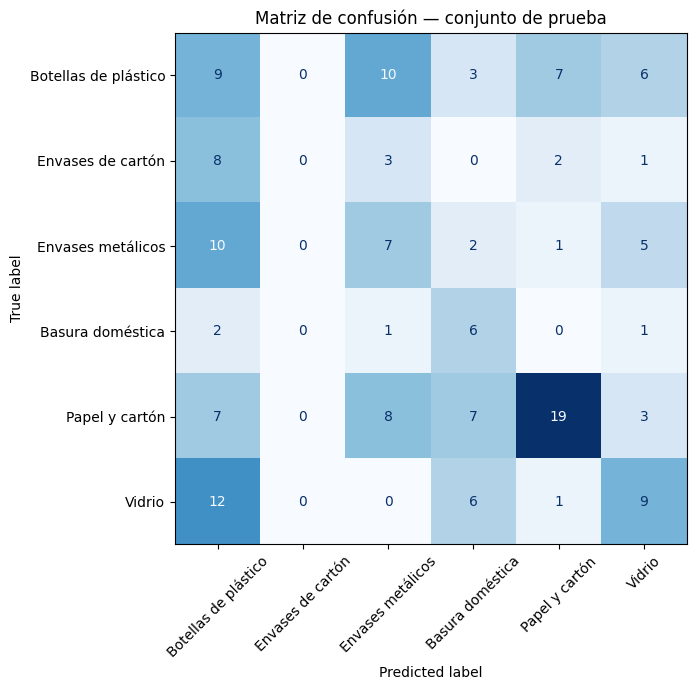

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Elegir el modelo usando los resultados de validación
modelo_final = modelo_ajustado


test_ds = crear_dataset(df_test)

loss_test, acc_test = modelo_final.evaluate(test_ds, verbose=0)

# Obtener predicciones manteniendo el mismo orden
probabilidades = modelo_final.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

y_real = (
    df_test["categoria"]
    .map(clase_a_id)
    .to_numpy(dtype=np.int32)
)

nombres_es = [
    "Botellas de plástico",
    "Envases de cartón",
    "Envases metálicos",
    "Basura doméstica",
    "Papel y cartón",
    "Vidrio"
]

print(f"Pérdida en prueba: {loss_test:.4f}")
print(f"Exactitud en prueba: {acc_test:.2%}\n")

print(classification_report(
    y_real,
    y_pred,
    labels=list(range(len(clases))),
    target_names=nombres_es,
    digits=3,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred,
    labels=list(range(len(clases))),
    display_labels=nombres_es,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax
)

ax.set_title("Matriz de confusión — conjunto de prueba")
plt.tight_layout()
plt.show()

### Comprobación de validación
La evaluación adicional conservada recuperó **70.88 %** y **0.7384** en validación, consistentes con el ajuste. Esto confirma la consistencia de esa evaluación en la sesión; no demuestra por sí solo el contenido de un archivo `.keras` externo, que no se adjuntó al notebook.

In [ ]:
# Recuperar la validación disponible sin entrenar
if "val_ds" in globals():
    val_revision_ds = val_ds

elif "df_val" in globals() and "crear_dataset" in globals():
    val_revision_ds = crear_dataset(df_val)

if "val_revision_ds" in globals():
    loss_revision, acc_revision = modelo_final.evaluate(
        val_revision_ds,
        verbose=0
    )

    print(f"Exactitud de validación: {acc_revision:.2%}")
    print(f"Pérdida de validación: {loss_revision:.4f}")

else:
    print("Falta reconstruir la validación.")
    for nombre in ["df_val", "df_val_revision", "crear_dataset", "raiz"]:
        estado = "disponible" if nombre in globals() else "falta"
        print(f"{nombre}: {estado}")

Exactitud de validación: 70.88%
Pérdida de validación: 0.7384


### Inspección posterior de diferencias visuales
Después de evaluar prueba se compararon ejemplos de las carpetas originales. En la muestra se observan objetos de entrenamiento verticales, centrados o sobre fondos sencillos y ejemplos de prueba girados, vistos desde arriba, borrosos o con fondos más complejos. La inspección usa las carpetas originales y no una nueva partición experimental.

Esto sugiere un cambio de distribución que puede contribuir a la diferencia de **38.83 puntos porcentuales** entre validación y prueba. Es una hipótesis basada en ejemplos, no una causa demostrada. También podrían influir ruido de etiquetas, similitudes no detectadas entre entrenamiento y validación y capacidad insuficiente de generalización. No se cambió el modelo después de esta inspección. Si se usara prueba para guiar nuevos ajustes, haría falta una evaluación independiente para medirlos.

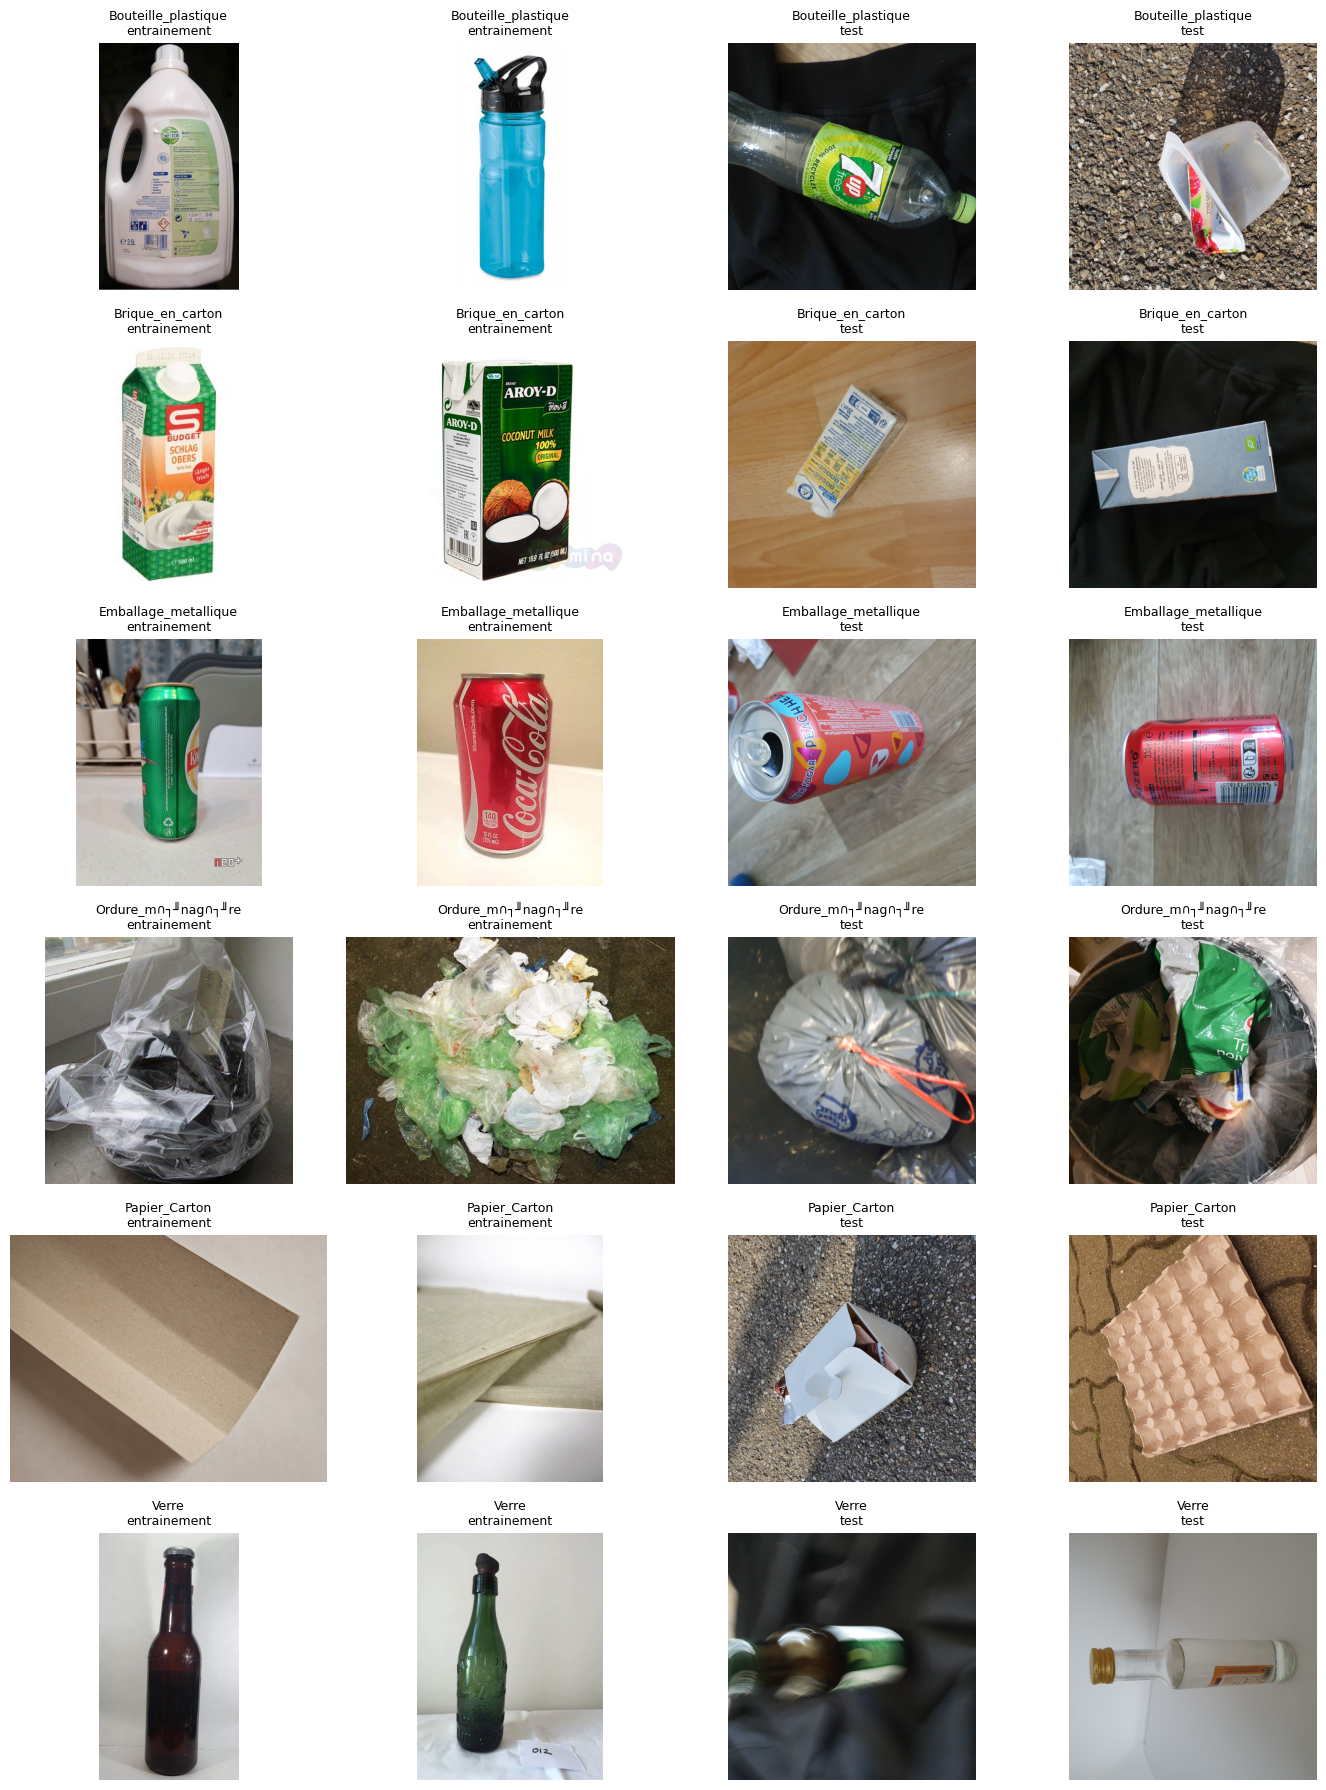

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

rng = random.Random(42)
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

fig, axes = plt.subplots(
    len(clases), 4,
    figsize=(14, 3 * len(clases)),
    squeeze=False
)

for fila, categoria in enumerate(clases):
    for bloque, particion in enumerate(["entrainement", "test"]):
        carpeta = Path(raiz) / particion / categoria

        imagenes = sorted(
            p for p in carpeta.rglob("*")
            if p.is_file() and p.suffix.lower() in extensiones
        )

        ejemplos = rng.sample(imagenes, min(2, len(imagenes)))

        for numero in range(2):
            ax = axes[fila, bloque * 2 + numero]
            ax.axis("off")

            if numero < len(ejemplos):
                with Image.open(ejemplos[numero]) as imagen:
                    ax.imshow(imagen.convert("RGBA"))

            ax.set_title(
                f"{categoria}\n{particion}",
                fontsize=9
            )

plt.tight_layout()
plt.show()

## 6. Conclusiones
Se implementó una CNN con Keras y TensorFlow que recibe imágenes y genera una de seis categorías. La limpieza identificó duplicados y escenas con etiquetas contradictorias; la partición de datos permitió comparar dos versiones sin seleccionar el ajuste a partir de prueba.

La combinación de tasa menor y entrenamiento adicional mejoró la validación de **69.57 % a 70.88 %**, pero el resultado en prueba fue **32.05 %** y el F1 macro **0.280**. Por ello, la mejora en validación no basta para afirmar que el sistema generaliza adecuadamente a escenas reales. El prototipo demuestra la implementación, pero su desempeño es insuficiente para automatizar una separación fiable.

Las limitaciones principales son la prueba pequeña y desigual, la ausencia de una auditoría completa de etiquetas y duplicados aproximados, la posible diferencia de condiciones de captura y una validación procedente de la misma carpeta que entrenamiento. Las puntuaciones softmax no están calibradas y el clasificador siempre elige una clase, incluso ante una imagen fuera de las categorías.

Como trabajo futuro se propone incorporar imágenes representativas de uso real, estudiar agrupación por objeto/sesión al separar datos, revisar etiquetas y duplicados perceptuales y experimentar con rotaciones, zoom y variaciones de iluminación solo en entrenamiento. También sería posible comparar transferencia de aprendizaje con esta CNN. Estas mejoras son propuestas: no se implementaron ni se les atribuyen resultados.

## 7. Aplicación
La función `predecir_imagen(ruta)` utiliza el mismo tratamiento de transparencia, tamaño y escala que entrenamiento. El modelo incluye `Rescaling`, por lo que no se divide de nuevo entre 255. La función devuelve categoría y puntuación softmax, y muestra la imagen. La carga interactiva de archivos requiere Google Colab.

Los tres ejemplos ejecutados se conservan debajo. Las salidas fueron **Vidrio (91.25 %)**, **Envases metálicos (63.20 %)** y **Papel y cartón (64.07 %)**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

traducciones = {
    "Bouteille_plastique": "Botellas de plástico",
    "Brique_en_carton": "Envases de cartón",
    "Emballage_metallique": "Envases metálicos",
    "Papier_Carton": "Papel y cartón",
    "Verre": "Vidrio"
}

def predecir_imagen(ruta):
    """Recibe una ruta y devuelve la categoría y su puntuación softmax."""
    alto, ancho = map(int, modelo_final.input_shape[1:3])

    # Mismo tratamiento de color y transparencia del entrenamiento
    with Image.open(ruta) as imagen:
        rgba = imagen.convert("RGBA")
        fondo = Image.new("RGBA", rgba.size, "white")
        original = Image.alpha_composite(fondo, rgba).convert("RGB")

    imagen_modelo = original.resize(
        (ancho, alto),
        resample=Image.Resampling.BILINEAR
    )

    entrada = np.asarray(imagen_modelo, dtype=np.float32)
    entrada = np.expand_dims(entrada, axis=0)

    # El modelo ya incluye la normalización de píxeles
    probabilidades = modelo_final.predict(entrada, verbose=0)[0]

    indice = int(np.argmax(probabilidades))
    categoria_original = clases[indice]

    categoria = (
        "Basura doméstica"
        if categoria_original.startswith("Ordure")
        else traducciones.get(categoria_original, categoria_original)
    )

    puntuacion = float(probabilidades[indice])

    plt.figure(figsize=(5, 5))
    plt.imshow(original)
    plt.title(
        f"Predicción: {categoria}\n"
        f"Puntuación del modelo: {puntuacion:.1%}"
    )
    plt.axis("off")
    plt.show()

    return {
        "categoria": categoria,
        "puntuacion_softmax": puntuacion
    }

print("Función lista para recibir una imagen.")

Función lista para recibir una imagen.


Saving Captura de pantalla 2026-11-13 a la(s) 7.06.30 p.m..png to Captura de pantalla 2026-11-13 a la(s) 7.06.30 p.m..png


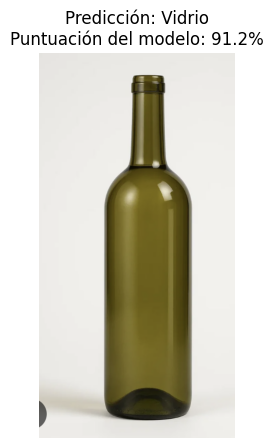

{'categoria': 'Vidrio', 'puntuacion_softmax': 0.912468433380127}


In [ ]:
from google.colab import files

subidos = files.upload()

for ruta in subidos:
    resultado = predecir_imagen(ruta)
    print(resultado)

Saving Captura de pantalla 2026-11-13 a la(s) 7.07.46 p.m..png to Captura de pantalla 2026-11-13 a la(s) 7.07.46 p.m..png


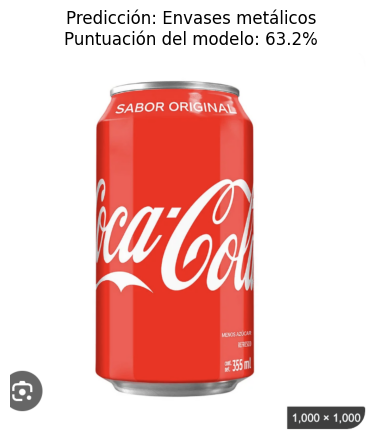

{'categoria': 'Envases metálicos', 'puntuacion_softmax': 0.6319686770439148}


In [ ]:
from google.colab import files

subidos = files.upload()

for ruta in subidos:
    resultado = predecir_imagen(ruta)
    print(resultado)

Saving Captura de pantalla 2026-11-13 a la(s) 7.10.54 p.m..png to Captura de pantalla 2026-11-13 a la(s) 7.10.54 p.m..png


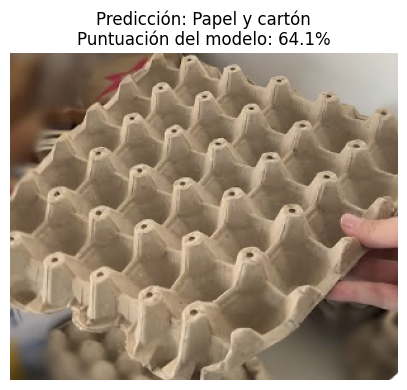

{'categoria': 'Papel y cartón', 'puntuacion_softmax': 0.6407200694084167}


In [ ]:
from google.colab import files

subidos = files.upload()

for ruta in subidos:
    resultado = predecir_imagen(ruta)
    print(resultado)